In [1]:
import os
import sys
import pickle
import numpy as np
import tensorflow as tf
from matplotlib import rcParams
import matplotlib.pyplot as plt

# ── Path setup ────────────────────────────────────────────────────────────
GLM_DIR = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model'
if GLM_DIR not in sys.path:
    sys.path.insert(0, GLM_DIR)

# ── Pipeline imports ───────────────────────────────────────────────────────
from synthetic_session import generate_synthetic_session
from core.session_pipeline import (
    generate_predictors,
    stack_design_matrices,
    prepare_features_for_glm,
    fit_glm_single_session,
)

# ── Plot style ─────────────────────────────────────────────────────────────
rcParams['font.family'] = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top'] = False

CONTEXT_NAMES  = {0: 'CG', 1: 'visual', 2: 'audio'}
CTX_COLORS     = {0: 'purple', 1: '#EC008C', 2: '#27AAE1'}

print("✓ Imports complete")

✓ Imports complete


In [2]:
# ── Synthetic session configuration ──────────────────────────────────────
# No real session data is needed — all trials are generated from scratch.
N_TRIALS_PER_CONTEXT = 100   # trials per context (300 total)
CORRECT_RATE         = 0.7   # fraction correct per context
SEED                 = 42

In [12]:
from simulated_neurons import SimulatedNeurons

# ── Generate fully synthetic session ────────────────────────────────────
# No real data needed. All 300 trials (100 per context) are generated from
# scratch with identical kinematics and fixed event timing:
#   - Turn onset at exactly frame 125 in every trial
#   - Exact 50/50 L/R choice per context
#   - 70% correct / 30% error per context
#   - 50/50 stimulus identity (independent of choice)
#   - ITI onset at frame 140 (15 frames post-turn) → outcome bump from +15 to +74
#
# include_velocity=False → 130 features (8 groups: pos, audio×2, visual×2,
#                           choice_spatial, turn_onset, outcome)

glm_data_dict = generate_synthetic_session(
    n_trials_per_context=N_TRIALS_PER_CONTEXT,
    correct_rate=CORRECT_RATE,
    seed=SEED,
)

design_matrices, pred_names, pred_info_raw = generate_predictors(
    glm_data_dict, include_velocity=True
)
X, Y_placeholder, metadata, group_indices = stack_design_matrices(
    glm_data_dict, design_matrices, pred_info_raw, neural_metric='deconv'
)
pred_info, feature_group_size = prepare_features_for_glm(pred_info_raw)

# Verify metadata fields
assert 'y_position' in metadata,          'y_position missing from metadata'
assert 'turn_frame_in_trial' in metadata, 'turn_frame_in_trial missing from metadata'

# turn_frame_in_trial should be 125 for every single frame
turn_vals = np.unique(metadata['turn_frame_in_trial'])
assert len(turn_vals) == 1 and turn_vals[0] == 125, \
    f'Expected all turn frames = 125, got {turn_vals}'

print(f'✓ X: {X.shape}  |  Predictor groups: {list(pred_info.keys())}')
print(f'  Turn-frame check: all trials have turn at frame {turn_vals[0]} ✓')

# ── Build simulated neurons ───────────────────────────────────────────────
# 14 neurons, one per predictor group/sub-group (clean one-hot ground truth).
# baseline_rate=0.004 events/frame ≈ 0.06 Hz (realistic for deconvolved Ca).
sim      = SimulatedNeurons(pred_info, metadata, X, baseline_rate=0.004, seed=SEED)
sim_data = sim.build_all_neurons()

Generated 300 synthetic trials (100 per context × 3 contexts)
  Frames / trial : 200  (turn at frame 125,  ITI at frame 140)
  Total frames   : 60,000
  Correct rate   : 70%

  Context   Ch  Outcome   N
  ------------------------------
  CG        L   error     13
  CG        L   correct   37
  CG        R   error     17
  CG        R   correct   33
  visual    L   error     16
  visual    L   correct   34
  visual    R   error     14
  visual    R   correct   36
  audio     L   error     10
  audio     L   correct   40
  audio     R   error     20
  audio     R   correct   30

Trials: 300 | Predictors: 150

Predictor groups:
  position_only       :  10  (cols 0–9)
  sound               :  20  (cols 10–29)
  visual              :  20  (cols 30–49)
  velocity            :  20  (cols 50–69)
  choice_spatial      :  60  (cols 70–129)
  turn_onset          :   8  (cols 130–137)
  outcome             :  12  (cols 138–149)
Predictor groups:
  position_only       : 10 features  (cols 0–9)
  a

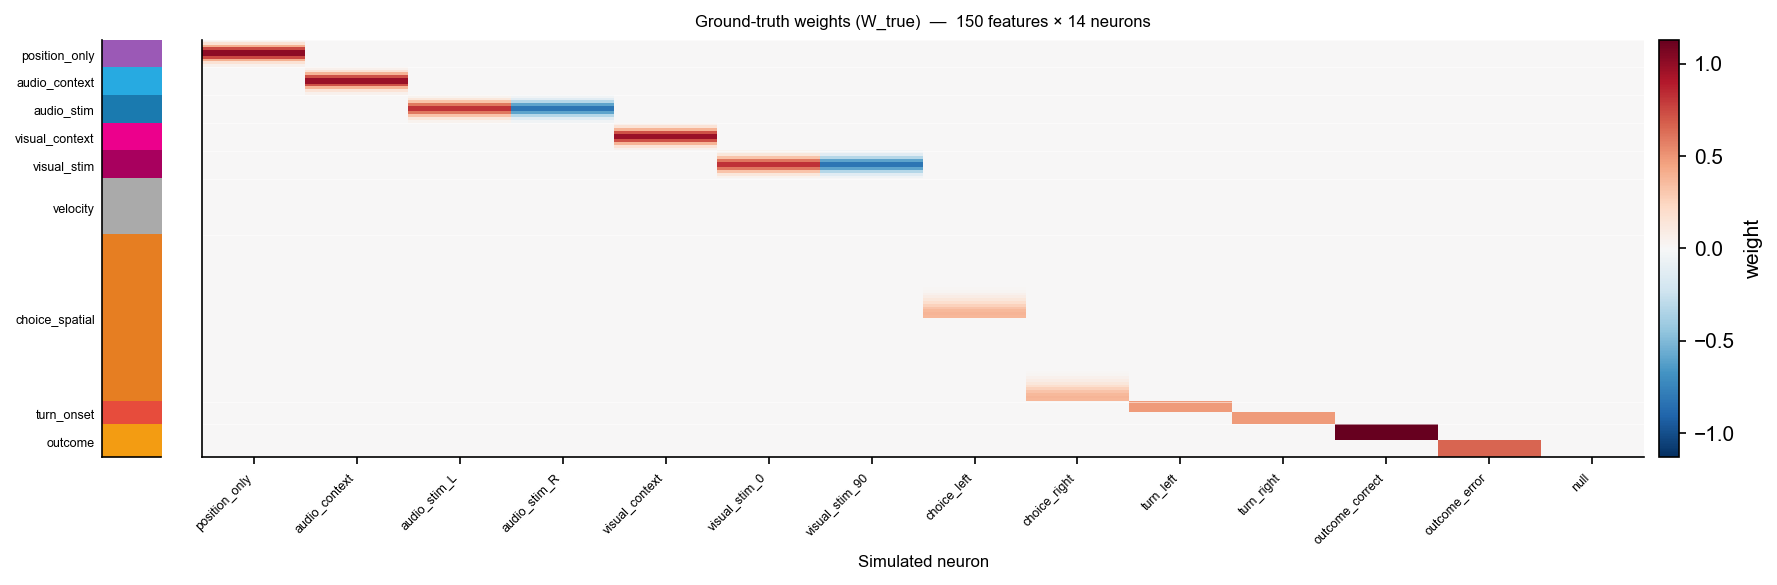

In [13]:
sim.plot_ground_truth_weights()    # heatmap: 130 features × 14 neurons (one lit block per neuron)

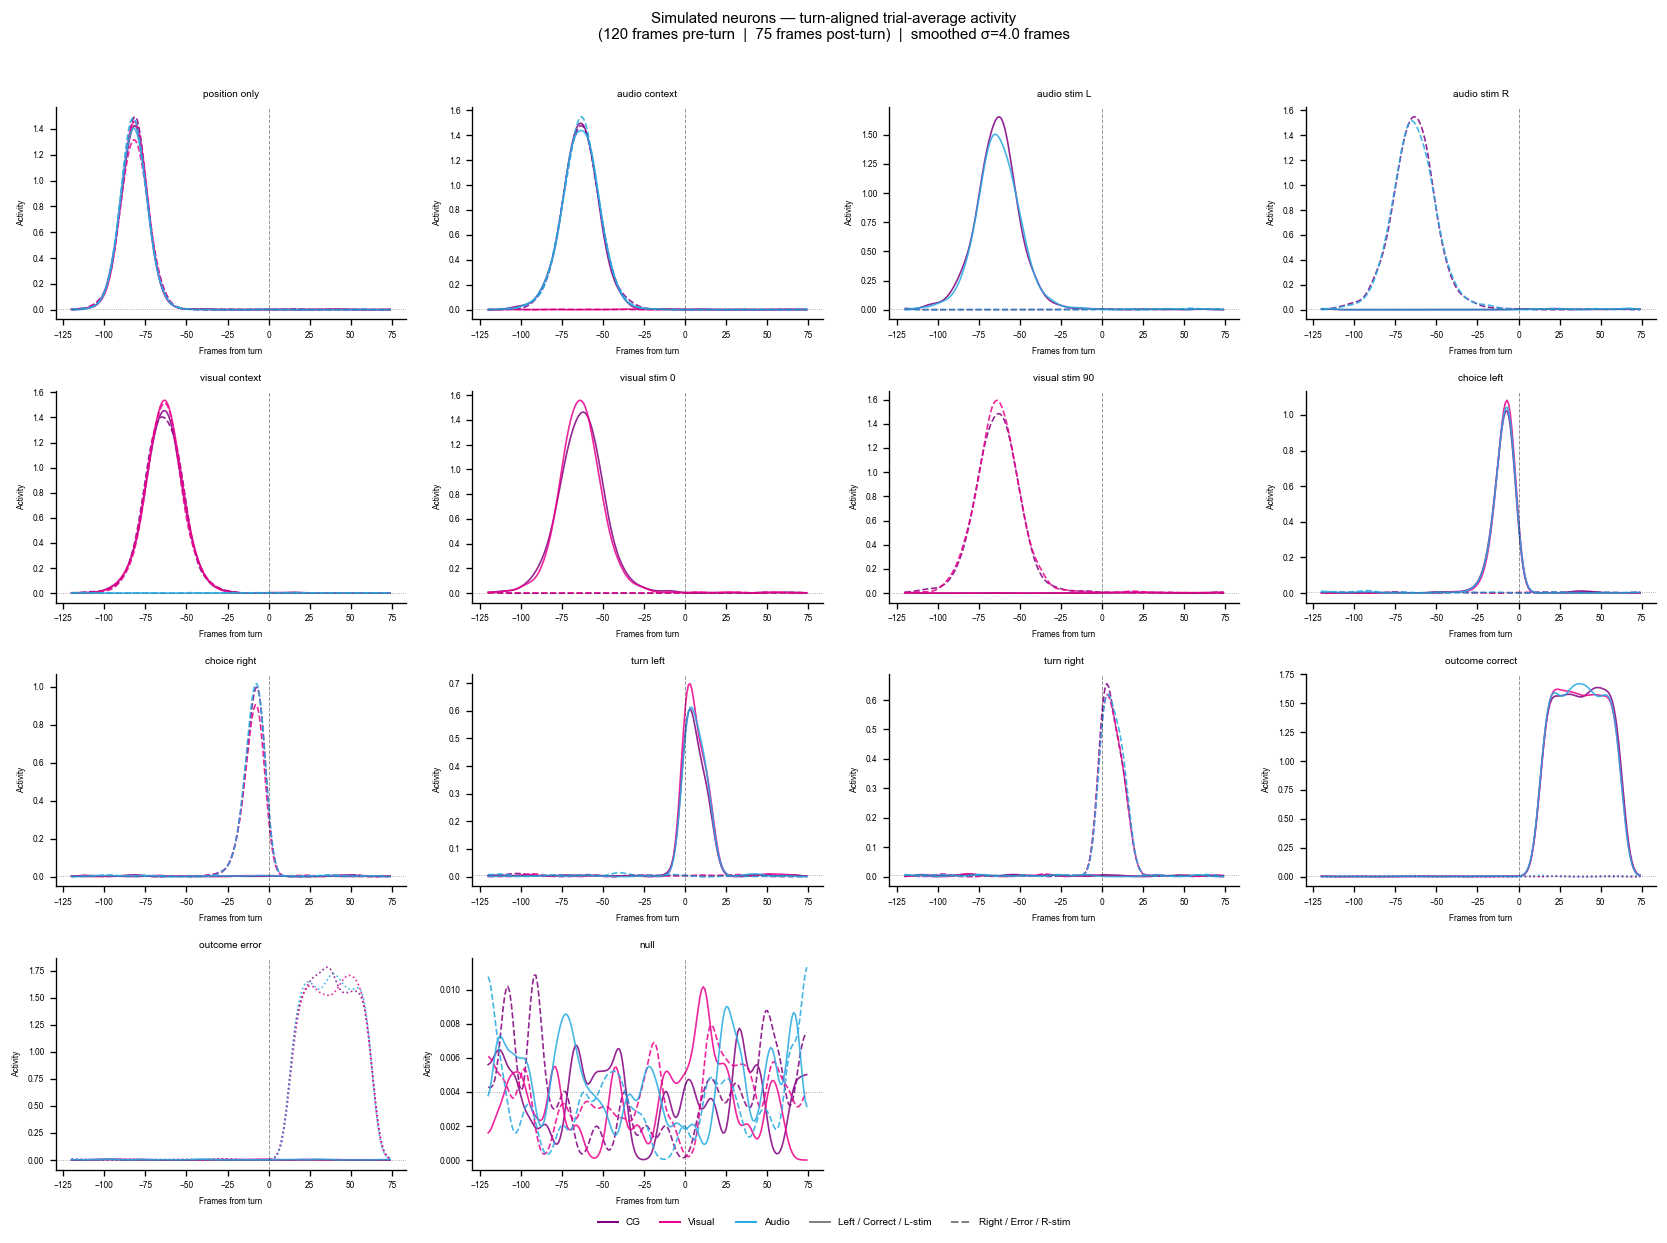

In [14]:
# Turn-aligned summary grid (120 frames pre-turn, 75 frames post-turn, σ=2 frame smoothing)
sim.plot_all_neurons_summary(n_pre_turn_frames=120, n_post_turn_frames=75, smooth_sigma=4.0)

# Single-neuron detail — turn-aligned with context × choice split
# Change neuron_idx to inspect any neuron (0–13)
#sim.plot_trial_average_turn_aligned(neuron_idx=0, n_pre_turn_frames=120, n_post_turn_frames=75, smooth_sigma=2.0)

In [15]:
model_cv, results, _, _ = fit_glm_single_session(
    X, sim_data['Y_sim'] * 10,   # ×10 to match scaling in open_glm_stacked_data
    metadata, feature_group_size, pred_info,
    mouse_ID='simulated', date='synthetic_v1',
)

Per-context balanced splits:
  ctx 0 (CG    ): 100 balanced trials | train 14,000 frames | test 6,000 frames
  ctx 1 (visual): 100 balanced trials | train 14,000 frames | test 6,000 frames
  ctx 2 (audio ): 100 balanced trials | train 14,000 frames | test 6,000 frames
Contexts used: [0, 1, 2]

Combined  train: 42,000 frames | test: 18,000 frames

Fitting GLM: 14 neurons | 42,000 train frames | 9 groups …
n_fold = 0
Lambda 0 iter 100 loss: -0.42680579 diff: 0.01441227
Lambda 0 iter 200 loss: -0.58154887 diff: 0.00153800
Lambda 0 iter 300 loss: -0.66507763 diff: 0.00083328
Lambda 0 iter 400 loss: -0.72510493 diff: 0.00059939
Lambda 0 iter 500 loss: -0.77268803 diff: 0.00047531
Lambda 0 iter 600 loss: -0.81210327 diff: 0.00039379
Lambda 0 iter 700 loss: -0.84552336 diff: 0.00033393
Lambda 0 iter 800 loss: -0.87427050 diff: 0.00028726
Lambda 0 iter 900 loss: -0.89925021 diff: 0.00024962
Lambda 0 iter 1000 loss: -0.92112768 diff: 0.00021863
Lambda 0 iter 1100 loss: -0.94041145 diff: 0.00019

In [17]:
for i, name in enumerate(sim_data['neuron_names']):
    print(f'{name:40s}  frac_dev = {results["test_frac_dev"][i]:.3f}')

N01_position_only                         frac_dev = 0.701
N02_audio_context                         frac_dev = 0.707
N03_audio_stim_L                          frac_dev = 0.699
N04_audio_stim_R                          frac_dev = 0.716
N05_visual_context                        frac_dev = 0.704
N06_visual_stim_0                         frac_dev = 0.700
N07_visual_stim_90                        frac_dev = 0.700
N08_choice_left                           frac_dev = 0.687
N09_choice_right                          frac_dev = 0.666
N10_turn_left                             frac_dev = 0.615
N11_turn_right                            frac_dev = 0.613
N12_outcome_correct                       frac_dev = 0.780
N13_outcome_error                         frac_dev = 0.813
N14_null                                  frac_dev = 0.000


In [8]:
# Quick weight recovery check — uncomment to run
# n = 7   # N08_choice_left (change to any index 0–13)
# plt.figure(figsize=(10, 3))
# plt.plot(sim_data['W_true'][:, n], label='ground truth', linewidth=1.5)
# plt.plot(results['weights'][:, n], label='recovered', alpha=0.7, linewidth=1)
# plt.axhline(0, color='grey', linewidth=0.5)
# plt.legend(); plt.xlabel('Predictor index')
# plt.title(f'Weights: {sim_data["neuron_names"][n]}')
# plt.tight_layout(); plt.show()

In [9]:
from core.glm_class import make_prediction

Y_sim  = sim_data['Y_sim']
Y_pred = make_prediction(X, results['weights'], results['w0'].flatten(), activation='exp')
sim._last_results = results

/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_neurons.py:765: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


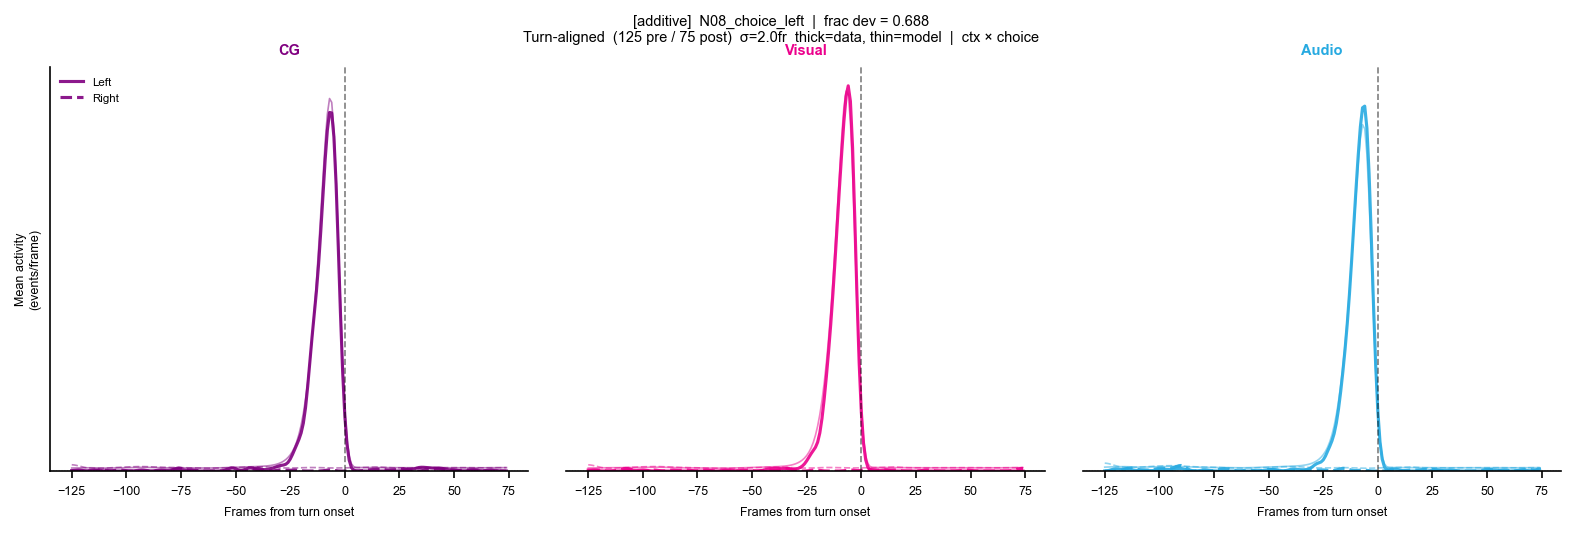

In [10]:
sim.plot_trial_average_turn_aligned(
    neuron_idx=7,   # N08_choice_left — change to any index 0–13
    Y_pred=Y_pred/10,
    n_pre_turn_frames=125,
    n_post_turn_frames=75,
    smooth_sigma=2.0,
)

Neuron 0: N01_position_only


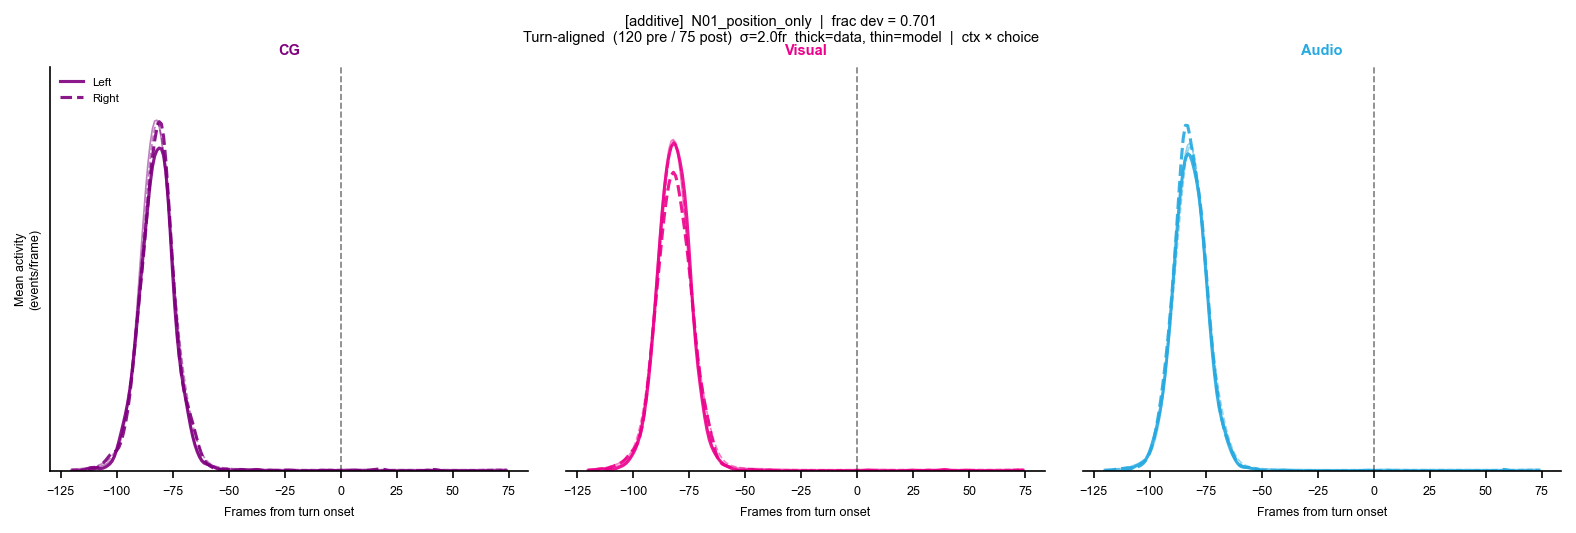

Neuron 1: N02_audio_context


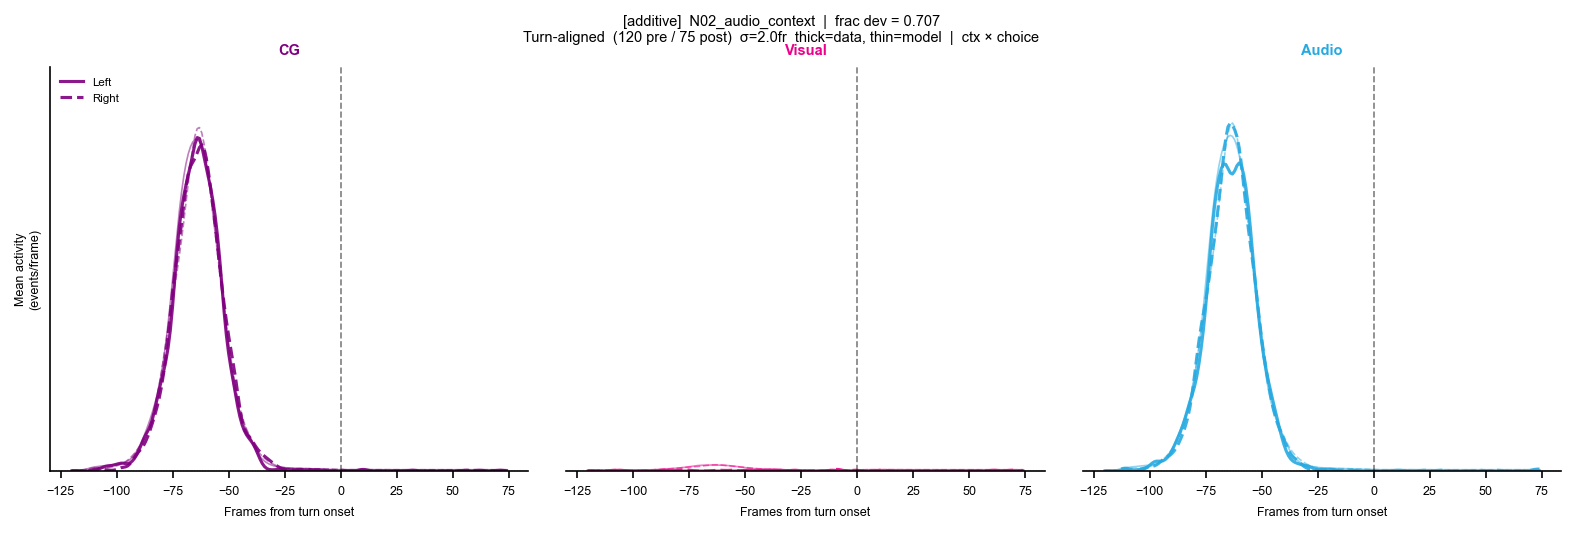

Neuron 2: N03_audio_stim_L


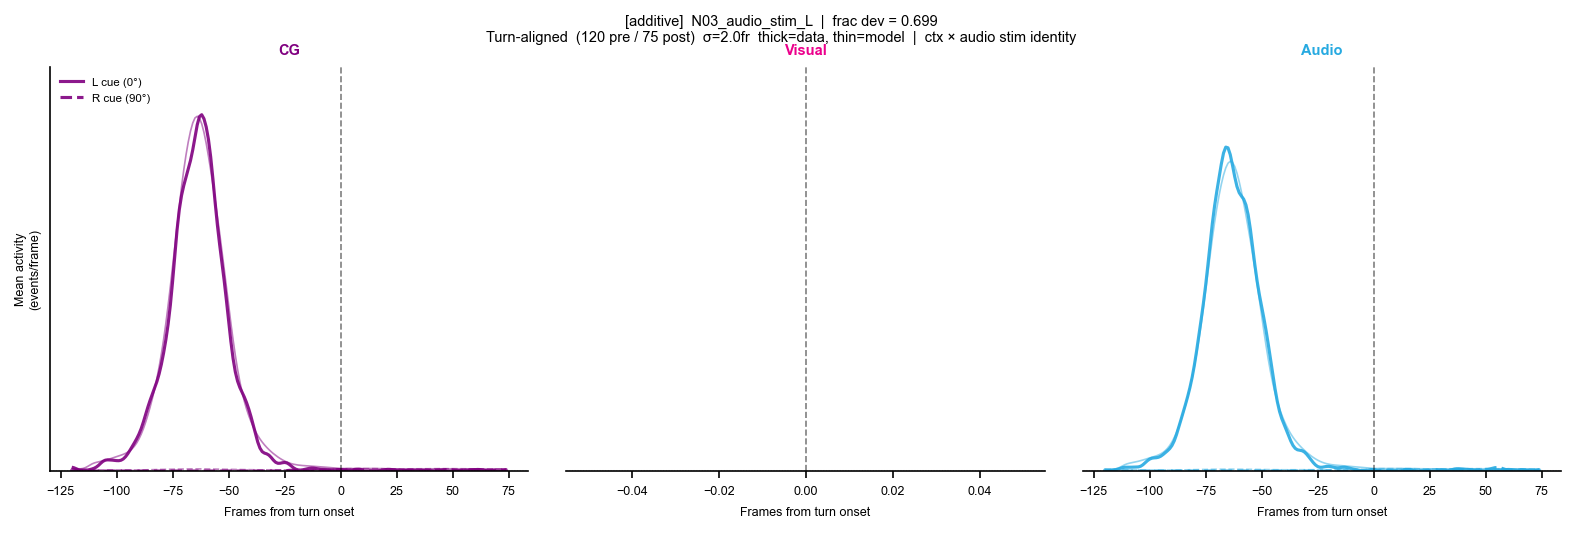

Neuron 3: N04_audio_stim_R


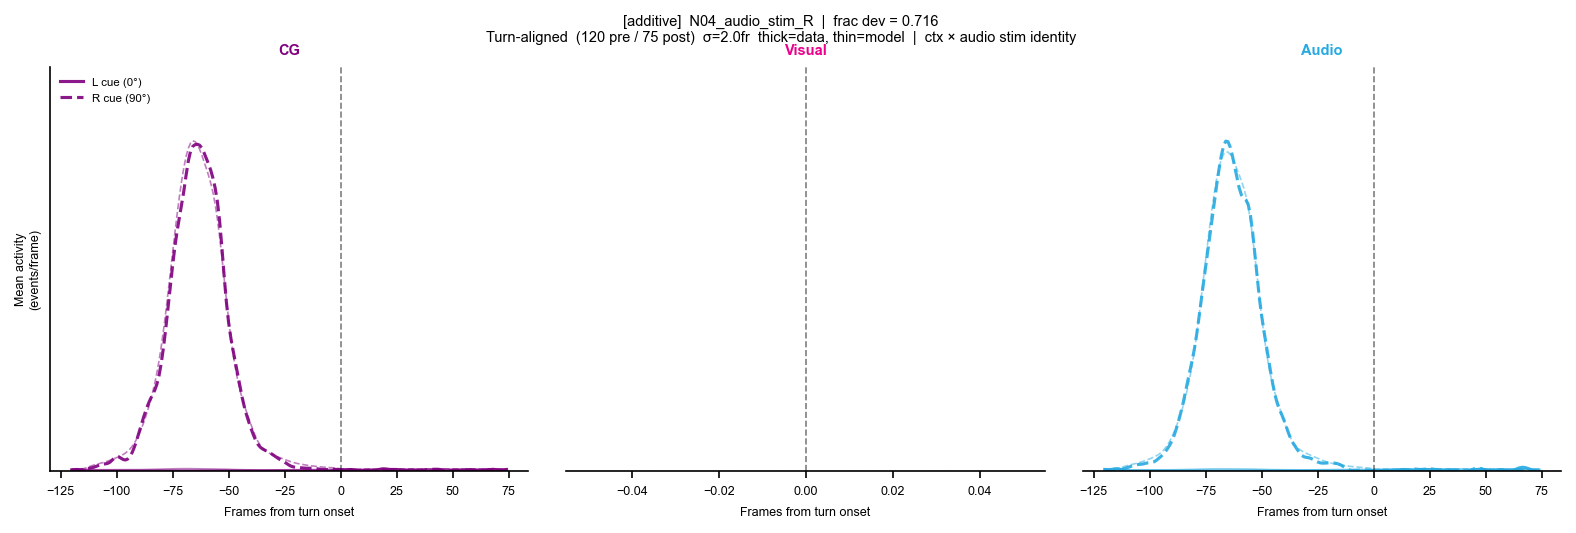

Neuron 4: N05_visual_context


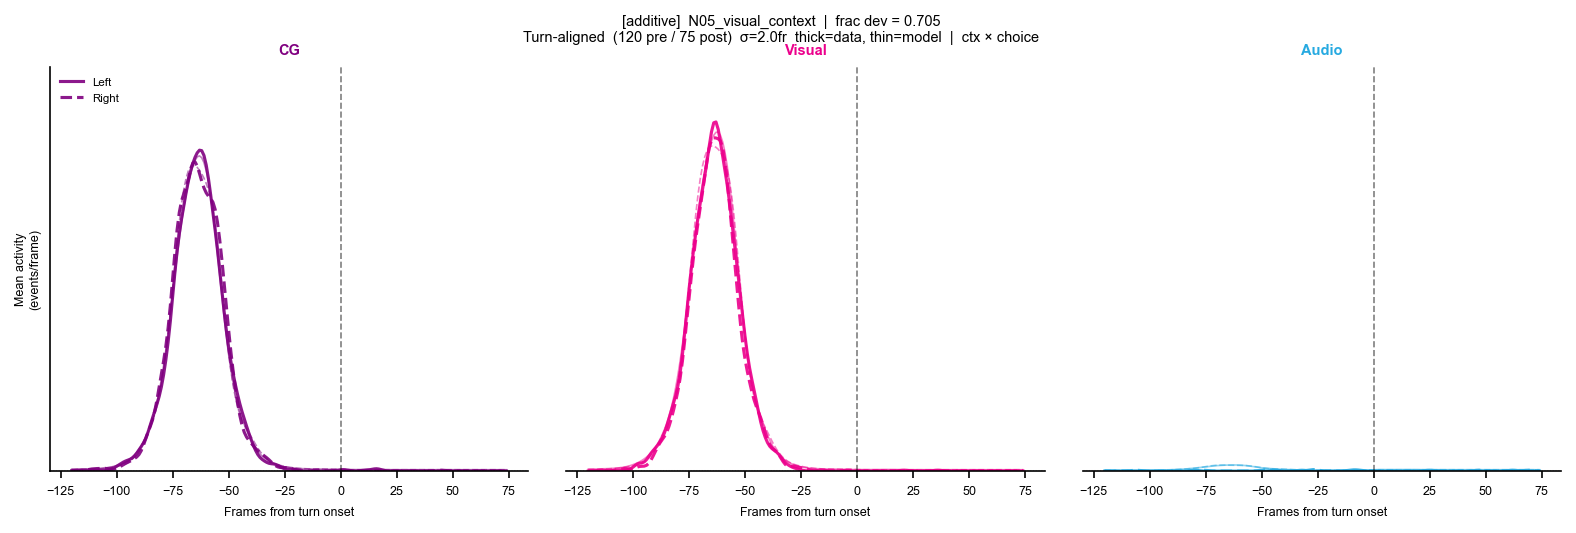

Neuron 5: N06_visual_stim_0


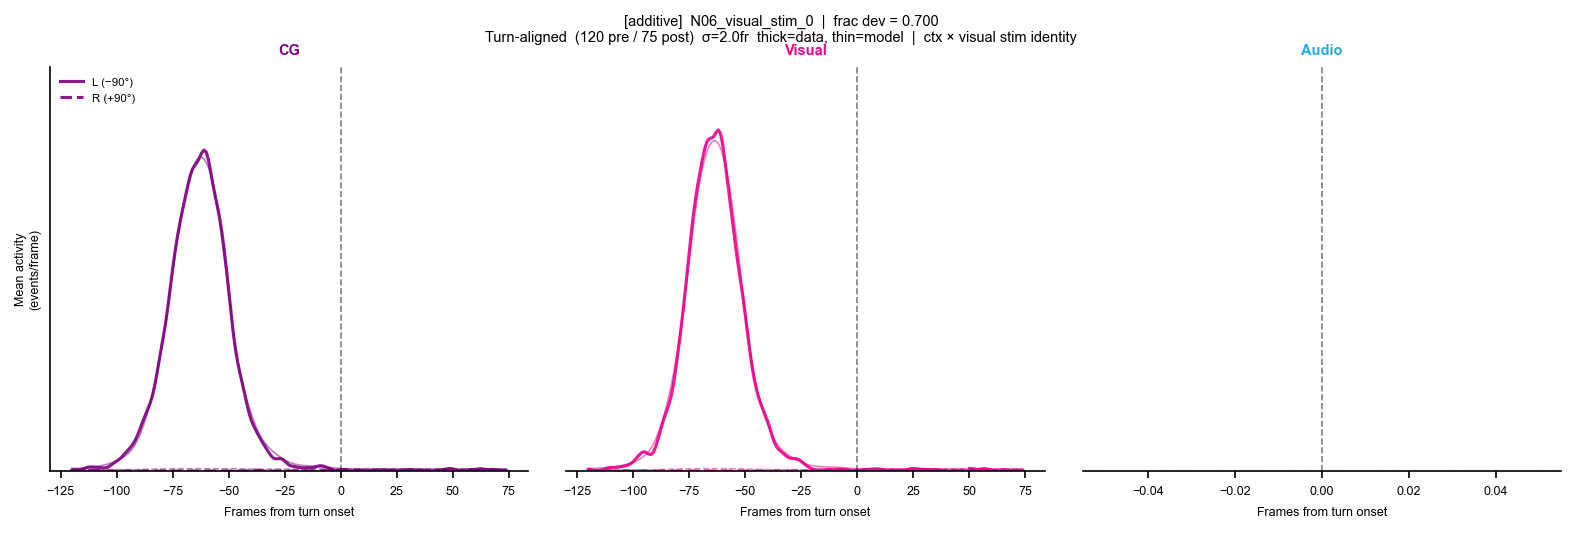

Neuron 6: N07_visual_stim_90


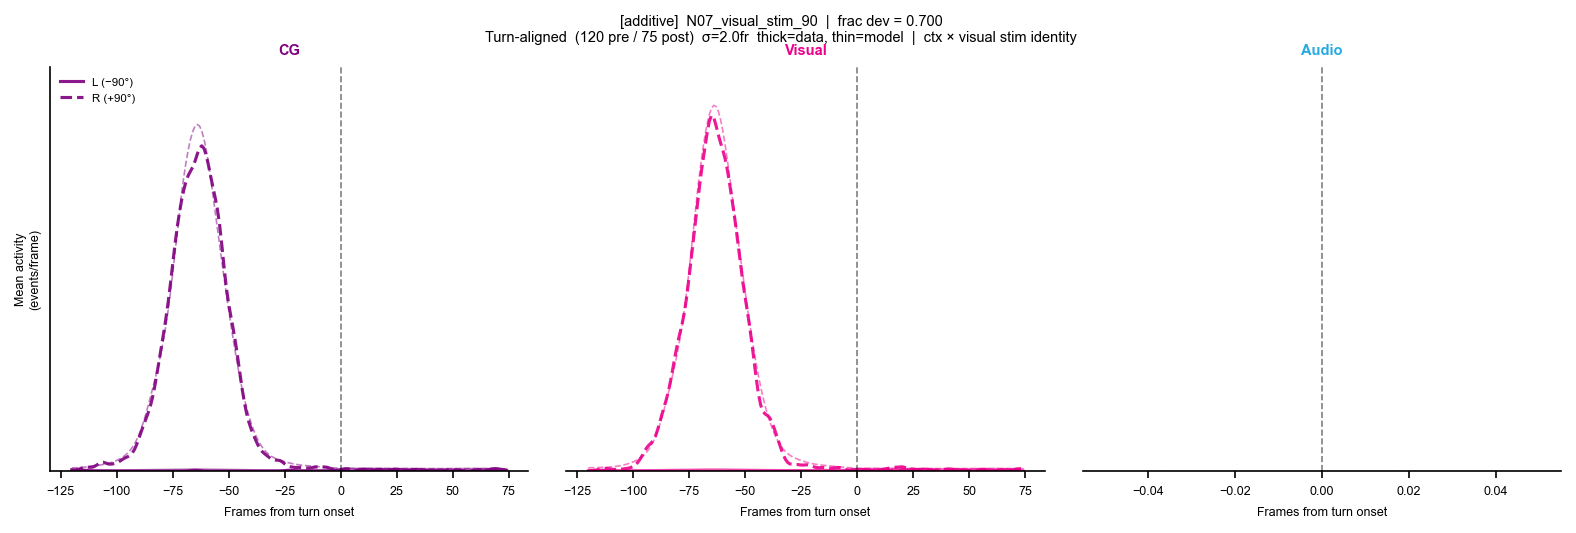

Neuron 7: N08_choice_left


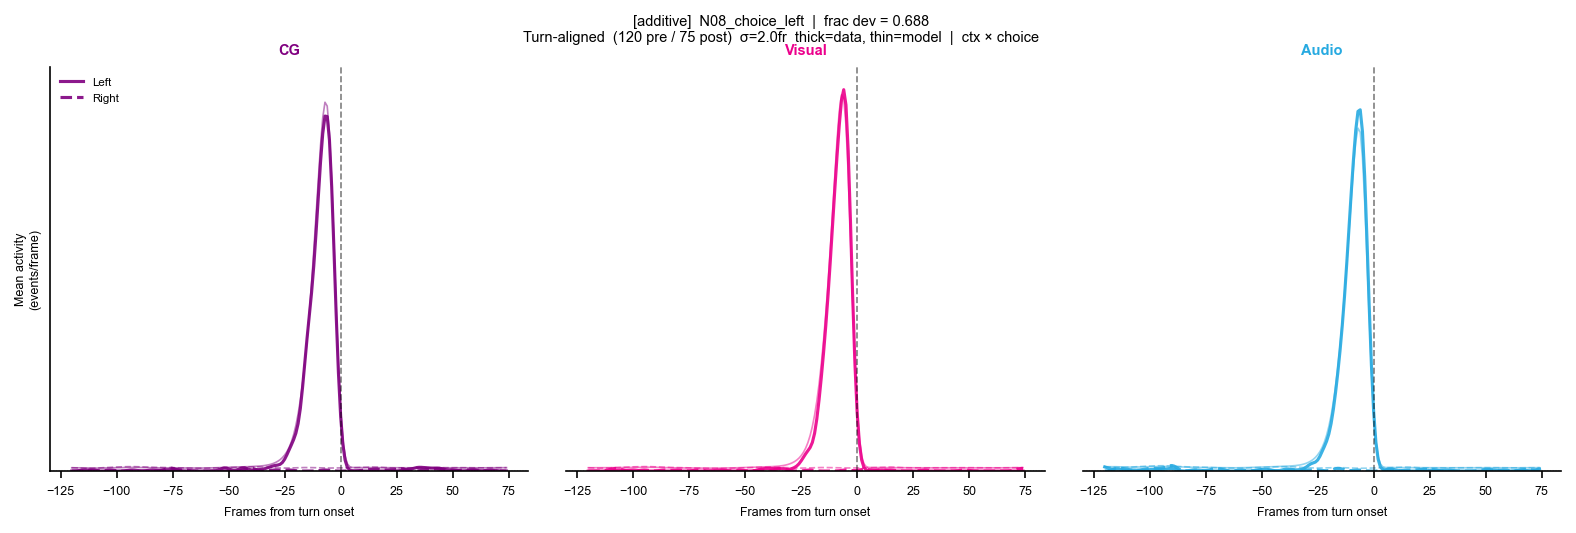

Neuron 8: N09_choice_right


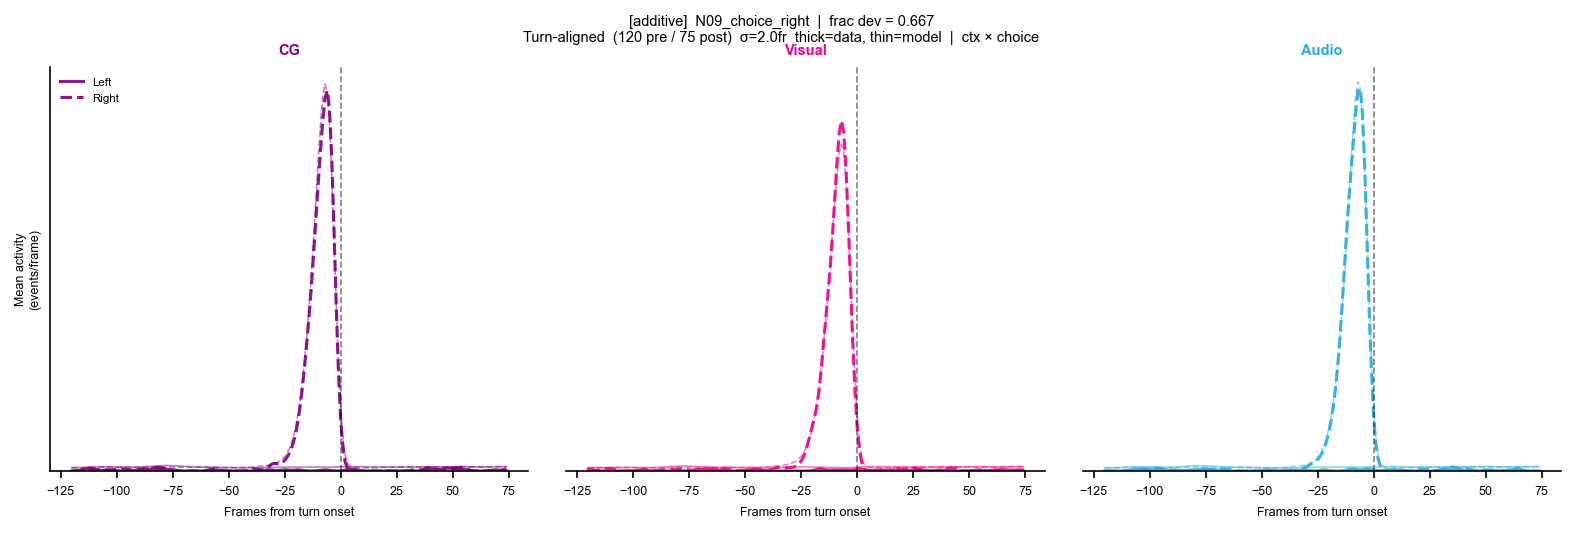

Neuron 9: N10_turn_left


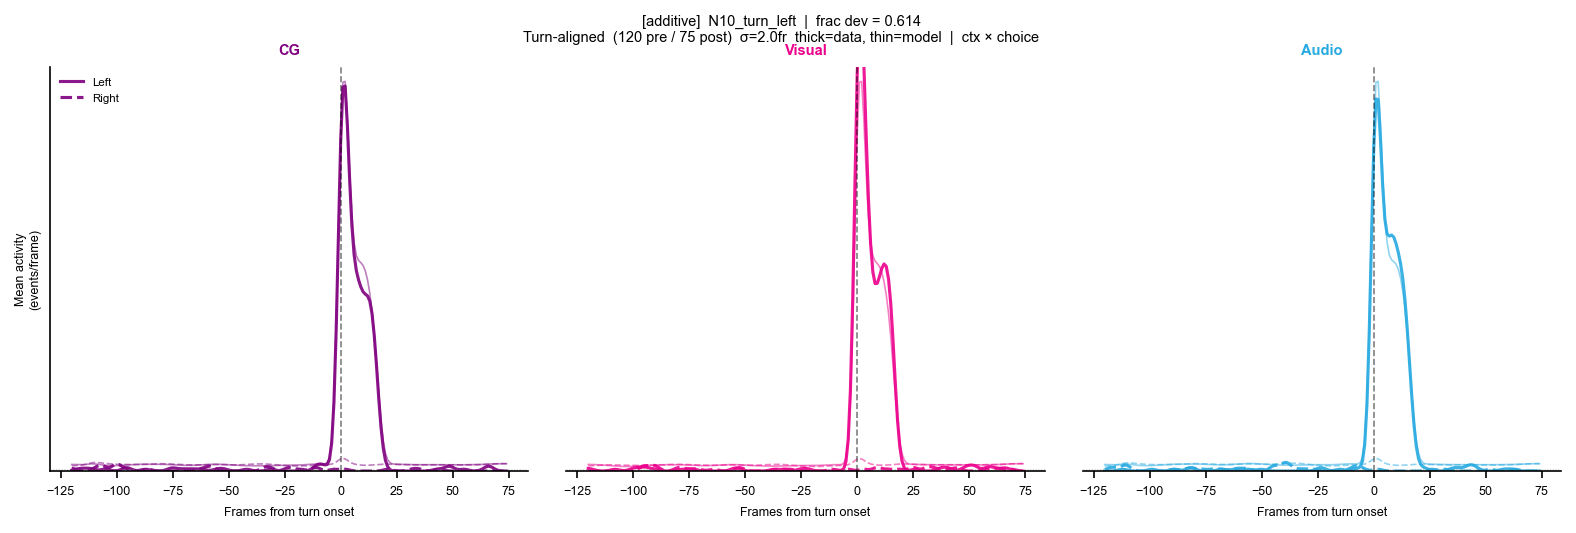

Neuron 10: N11_turn_right


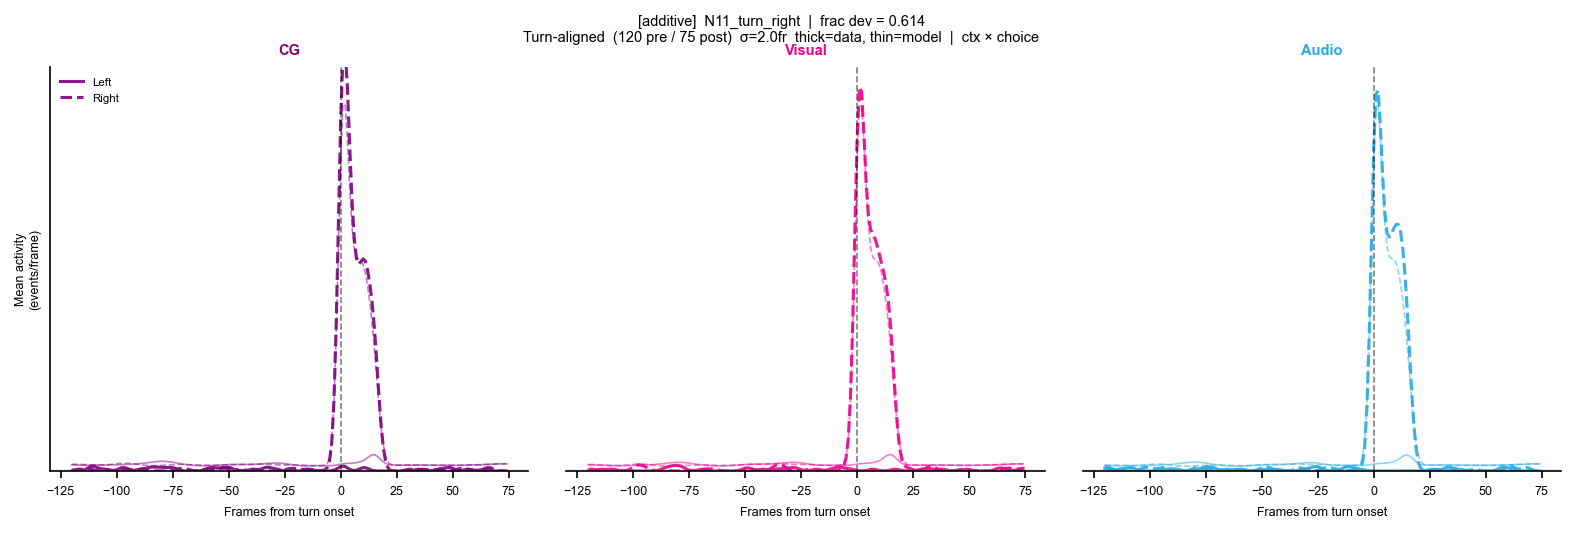

Neuron 11: N12_outcome_correct


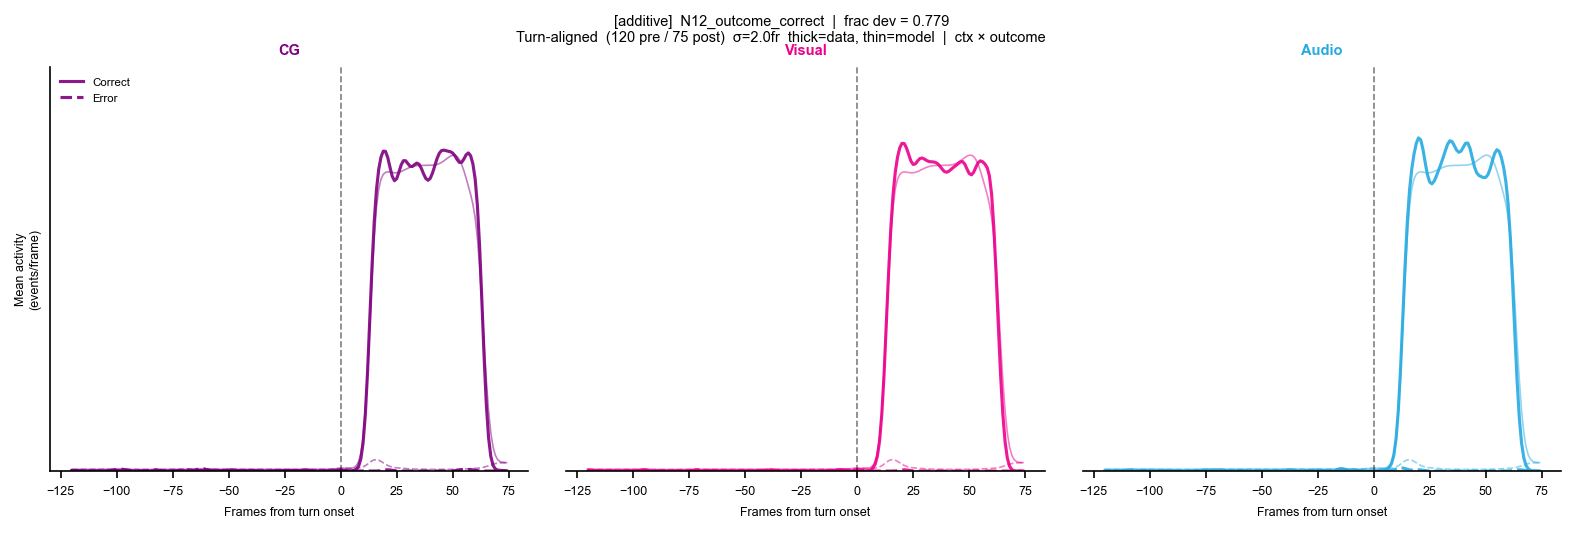

Neuron 12: N13_outcome_error


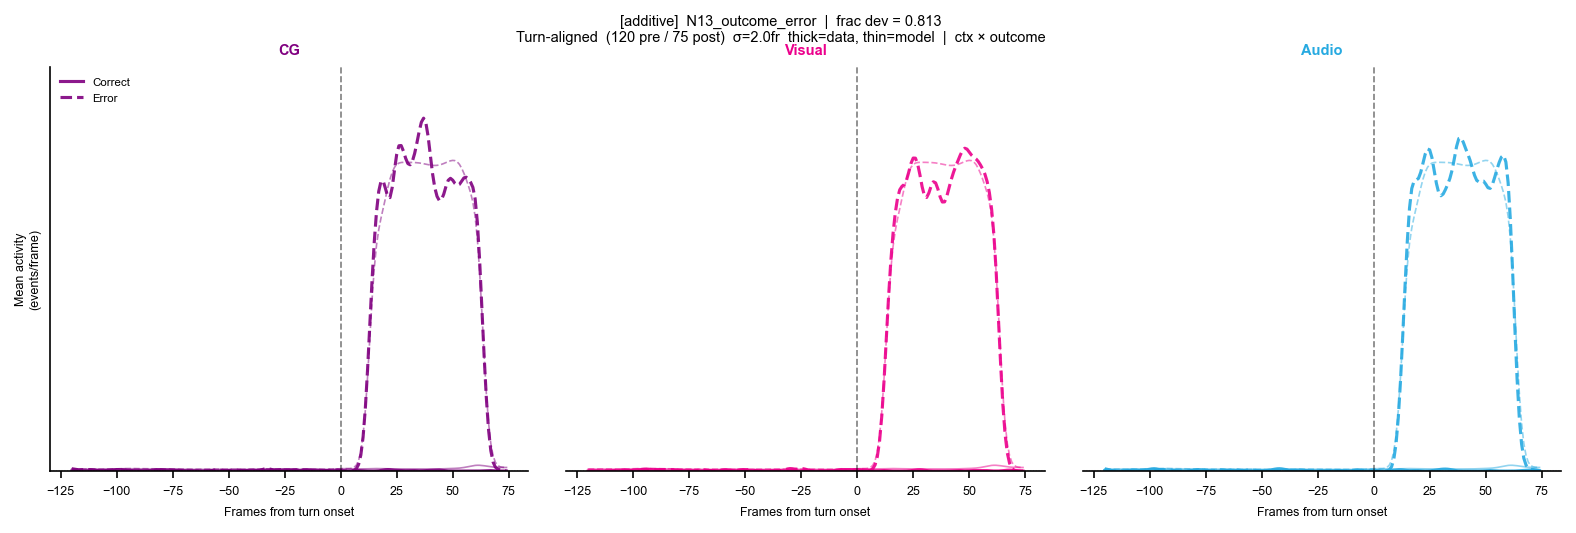

Neuron 13: N14_null


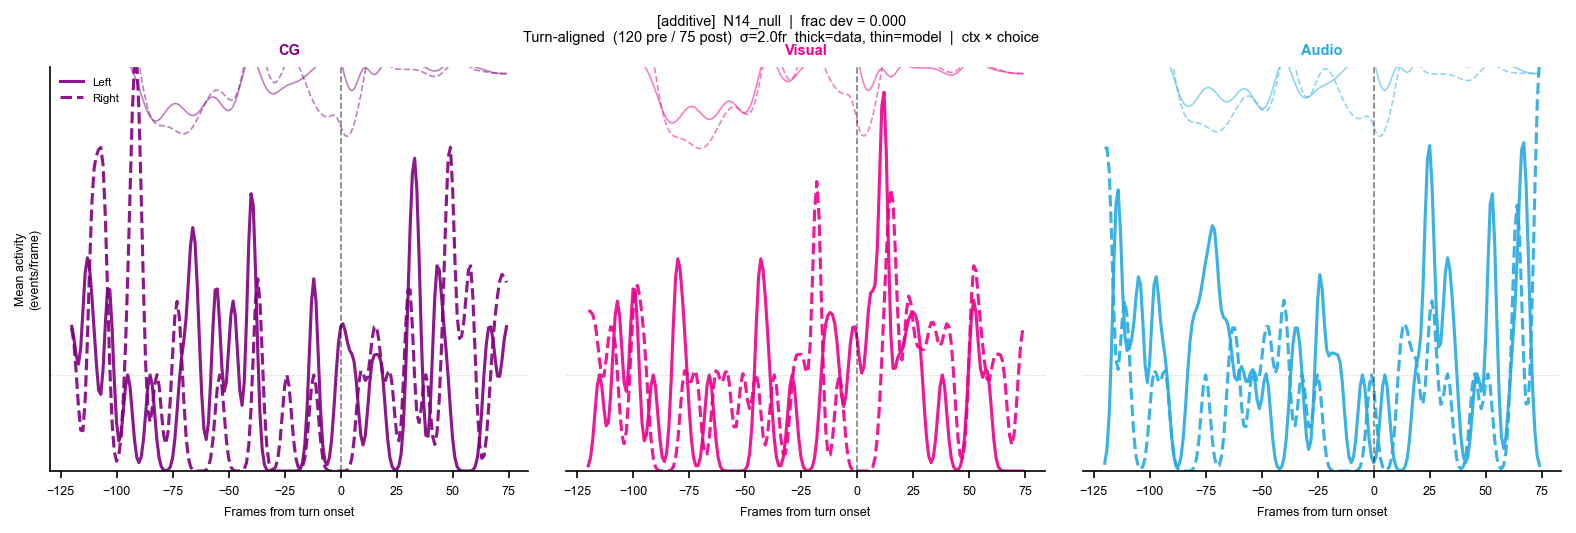

In [11]:
from core.glm_class import make_prediction

Y_sim  = sim_data['Y_sim']
Y_pred = make_prediction(X, results['weights'], results['w0'].flatten(), activation='exp')

# Store results on sim object so frac_dev appears in plot titles
sim._last_results = results

# ── Turn-aligned trial-average plots for all 19 neurons ──────────────────
# thick lines = data, thin lines = model prediction
# x-axis: frames relative to turn onset (−120 … 0 … 75)
# vertical dashed line at 0 = turn onset

for i, name in enumerate(sim_data['neuron_names']):
    print(f'Neuron {i}: {name}')
    sim.plot_trial_average_turn_aligned(
        neuron_idx=i,
        Y_pred=Y_pred / 10,              # pass None to show data only
        n_pre_turn_frames=120,
        n_post_turn_frames=75,
        smooth_sigma=2.0,           # Gaussian smoothing: σ=2 frames ≈ 128 ms at 15.6 Hz
    )